# Silchar Road Accident Risk — Exploratory Data Analysis
**Stages covered: 1 Prepare (data quality) and 2 Profile (time, vehicle, severity, exposure), plus location-level EPDO screening and a spatial first look.**

> ⚠️ All crash records and the 1–5 location scores are **synthetic** (seed 42), generated to follow the rules described in the project deck. Findings demonstrate the *method*, not observed Silchar conditions.

**Contents:** 1 Setup · 2 Data quality · 3 Temporal patterns · 4 Vehicles & collisions · 5 Severity · 6 Locations & EPDO · 7 Exposure attributes · 8 Spatial view · 9 Count distribution · 10 Key findings

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import os, warnings; warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)

ACC, GREY, DARK = "#C8442B", "#9AA5B1", "#1F3A5F"
plt.rcParams.update({"figure.dpi":110, "axes.spines.top":False, "axes.spines.right":False,
                     "axes.titleweight":"bold", "axes.titlesize":12, "figure.facecolor":"white"})
SEV_ORDER = ["Fatal","Grievous","Minor","Non-injury"]
SEV_COL = {"Fatal":"#8E1B10","Grievous":"#D9622B","Minor":"#EBB55B","Non-injury":"#B9C3CE"}
EPDO = {"Fatal":10,"Grievous":4,"Minor":2,"Non-injury":1}      # weights from the deck
def save(name): plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight"); plt.show()

X = "Silchar_Synthetic_Datasets.xlsx"
crashes = pd.read_excel(X, "Crashes", parse_dates=["date"])
locs    = pd.read_excel(X, "Locations")
panel   = pd.read_excel(X, "Monthly_Panel")
crashes["epdo"] = crashes.severity.map(EPDO)
crashes["serious"] = crashes.severity.isin(["Fatal","Grievous"])
print(crashes.shape, locs.shape, panel.shape)
crashes.head()

(949, 20) (14, 10) (1008, 15)


,crash_id,date,time,hour,location_id,location,latitude,longitude,vehicle_type,collision_type,severity,persons_killed,persons_injured,year,month,day_of_week,monsoon_flag,night_flag,epdo,serious
0,C0001,2019-01-01,13:30,13,L11,Medical College (Ghungoor),24.769738,92.785708,Auto/E-rickshaw,Hit fixed object,Non-injury,0,0,2019,1,Tuesday,0,0,1,False
1,C0002,2019-01-07,12:23,12,L01,Premtola,24.819706,92.798060,Truck/Lorry,Right-angle,Minor,0,1,2019,1,Monday,0,0,2,False
2,C0003,2019-01-09,19:17,19,L08,Meherpur,24.804248,92.781681,Auto/E-rickshaw,Side-swipe,Minor,0,1,2019,1,Wednesday,0,1,2,False
3,C0004,2019-01-10,11:37,11,L03,Ambicapatty,24.828384,92.794562,Two-wheeler,Right-angle,Minor,0,2,2019,1,Thursday,0,0,2,False
4,C0005,2019-01-14,20:21,20,L06,Rangirkhari,24.816176,92.789857,Car/SUV,Right-angle,Fatal,1,0,2019,1,Monday,0,1,10,True


## 2 · Data preparation & quality checks

In [2]:
print("Shape:", crashes.shape)
print("Date range:", crashes.date.min().date(), "→", crashes.date.max().date())
print("Duplicate crash_id:", crashes.crash_id.duplicated().sum(), "| fully duplicated rows:", crashes.drop(columns="crash_id").duplicated().sum())
print("Missing values per column:\n", crashes.isna().sum()[lambda s: s>0] if crashes.isna().any().any() else "none")
print("\nHour range:", crashes.hour.min(), "-", crashes.hour.max(),
      "| lat range:", crashes.latitude.min().round(4), "-", crashes.latitude.max().round(4),
      "| lon range:", crashes.longitude.min().round(4), "-", crashes.longitude.max().round(4))
print("Crashes in 'Fatal' with 0 killed:", ((crashes.severity=="Fatal") & (crashes.persons_killed==0)).sum(),
      "| non-fatal with killed>0:", ((crashes.severity!="Fatal") & (crashes.persons_killed>0)).sum())
print("Panel completeness: %d location-months (expected %d = 14 × 72)" % (len(panel), 14*72))
print("Crash total in panel equals record count:", panel.crash_count.sum() == len(crashes))

Shape: (949, 20)
Date range: 2019-01-01 → 2024-12-31
Duplicate crash_id: 0 | fully duplicated rows: 0
Missing values per column:
 none

Hour range: 0 - 23 | lat range: 24.753 - 24.8524 | lon range: 92.7261 - 92.8187
Crashes in 'Fatal' with 0 killed: 0 | non-fatal with killed>0: 0
Panel completeness: 1008 location-months (expected 1008 = 14 × 72)
Crash total in panel equals record count: True


In [3]:
summary = pd.DataFrame({
    "Records": [len(crashes)], "Locations": [crashes.location.nunique()],
    "Months": [panel[["year","month"]].drop_duplicates().shape[0]],
    "Fatal crashes": [(crashes.severity=="Fatal").sum()],
    "Persons killed": [crashes.persons_killed.sum()], "Persons injured": [crashes.persons_injured.sum()]}).T
summary.columns = ["Value"]; summary

,Value
Records,949
Locations,14
Months,72
Fatal crashes,79
Persons killed,92
Persons injured,889


**Reading:** no missing values, duplicates or impossible values, as expected for generated data. With real police/iRAD records, this section is where you would handle missing coordinates, free-text location names, and inconsistent severity coding. Fatal crashes and persons killed reconcile.

## 3 · Temporal patterns

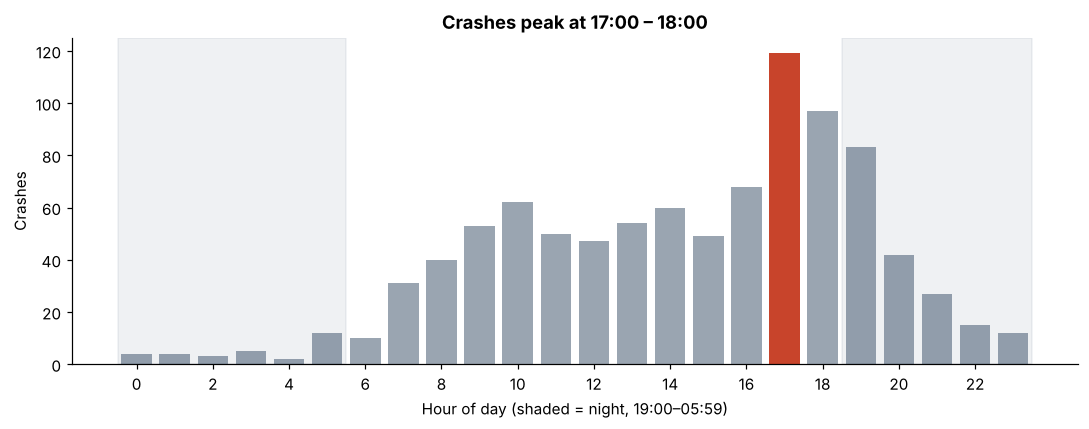

Peak hour: 17:00 (119 crashes, 12.5%)
Night share (19:00–05:59): 22.0%
Top-3 hours: {17: 119, 18: 97, 19: 83}


In [4]:
fig, ax = plt.subplots(figsize=(10,4))
h = crashes.hour.value_counts().reindex(range(24), fill_value=0)
ax.bar(h.index, h.values, color=[ACC if i==h.idxmax() else GREY for i in h.index])
ax.axvspan(18.5, 23.5, color="#1F3A5F", alpha=.07); ax.axvspan(-.5, 5.5, color="#1F3A5F", alpha=.07)
ax.set(xlabel="Hour of day (shaded = night, 19:00–05:59)", ylabel="Crashes", xticks=range(0,24,2))
ax.set_title(f"Crashes peak at {h.idxmax()}:00 – {h.idxmax()+1}:00")
save("01_hourly")
print(f"Peak hour: {h.idxmax()}:00 ({h.max()} crashes, {h.max()/len(crashes):.1%})")
print(f"Night share (19:00–05:59): {crashes.night_flag.mean():.1%}")
print("Top-3 hours:", h.nlargest(3).to_dict())

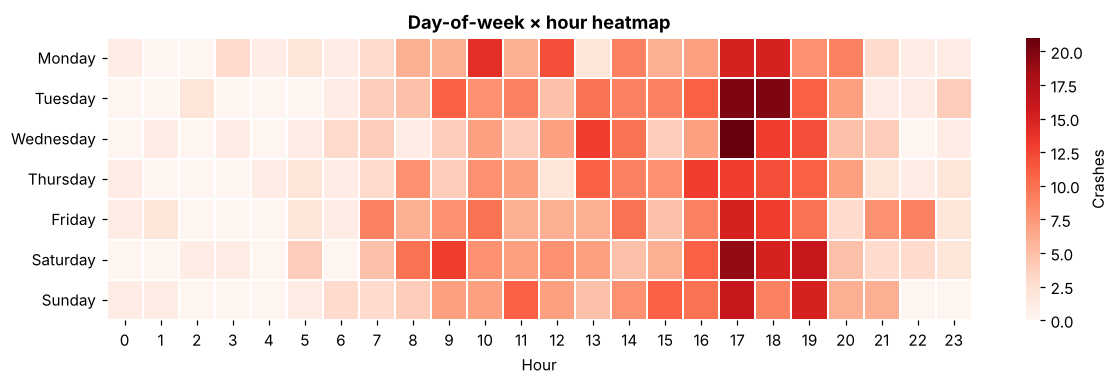

{'Monday': 131, 'Tuesday': 148, 'Wednesday': 123, 'Thursday': 126, 'Friday': 141, 'Saturday': 149, 'Sunday': 131}
Uniform-by-weekday test: χ²=4.8, p=0.565


In [5]:
dow_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
heat = crashes.pivot_table(index="day_of_week", columns="hour", values="crash_id", aggfunc="count", fill_value=0).reindex(dow_order)
fig, ax = plt.subplots(figsize=(11,3.6))
sns.heatmap(heat, cmap="Reds", cbar_kws={"label":"Crashes"}, ax=ax, linewidths=.3, linecolor="white")
ax.set(xlabel="Hour", ylabel=""); ax.set_title("Day-of-week × hour heatmap")
save("02_dow_hour_heatmap")
d = crashes.day_of_week.value_counts().reindex(dow_order)
chi = stats.chisquare(d)
print(d.to_dict()); print(f"Uniform-by-weekday test: χ²={chi.statistic:.1f}, p={chi.pvalue:.3f}")

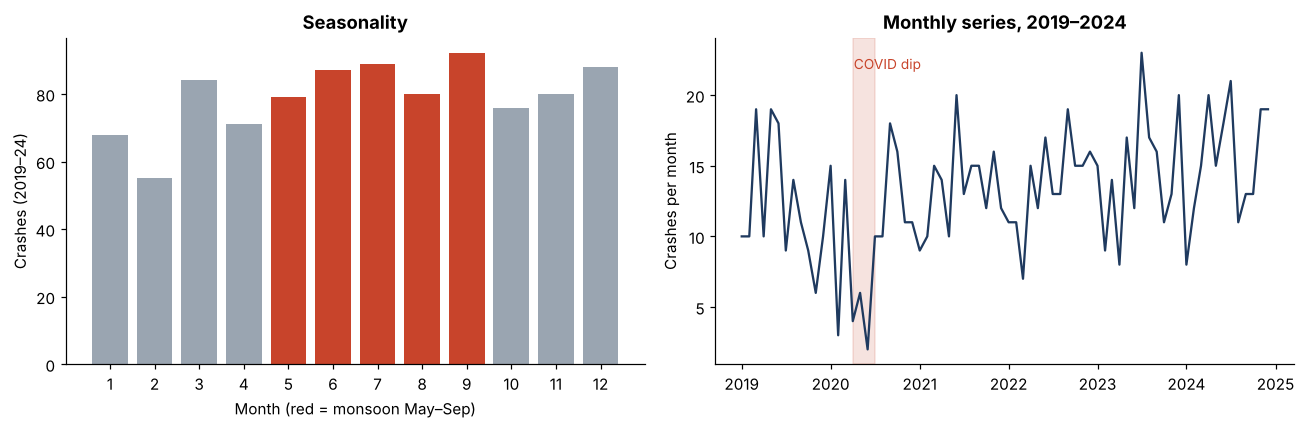

Monsoon (May–Sep) share: 45.0% vs calendar share 41.7%
Binomial test vs calendar share: p = 0.038
Yearly totals: {2019: 145, 2020: 120, 2021: 161, 2022: 164, 2023: 175, 2024: 184}


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
m = crashes.groupby("month").size()
axes[0].bar(m.index, m.values, color=[ACC if 5<=i<=9 else GREY for i in m.index])
axes[0].set(xlabel="Month (red = monsoon May–Sep)", ylabel="Crashes (2019–24)", xticks=range(1,13)); axes[0].set_title("Seasonality")
ym = crashes.groupby(["year","month"]).size().reset_index(name="n")
ym["t"] = pd.to_datetime(dict(year=ym.year, month=ym.month, day=1))
axes[1].plot(ym.t, ym.n, color=DARK, lw=1.5); axes[1].axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2020-06-30"), color=ACC, alpha=.15)
axes[1].text(pd.Timestamp("2020-04-05"), ym.n.max()*.95, "COVID dip", color=ACC, fontsize=9)
axes[1].set(ylabel="Crashes per month"); axes[1].set_title("Monthly series, 2019–2024")
save("03_seasonality_trend")
mon = crashes.monsoon_flag.mean()
exp = 5/12
obs = crashes.monsoon_flag.sum()
print(f"Monsoon (May–Sep) share: {mon:.1%} vs calendar share {exp:.1%}")
print("Binomial test vs calendar share: p = %.3f" % stats.binomtest(int(obs), len(crashes), exp).pvalue)
print("Yearly totals:", crashes.year.value_counts().sort_index().to_dict())

**Reading:** a clear evening peak at 17:00 (shoulders at 16:00 and 18:00) and a lower, flatter late-morning plateau; roughly one crash in five happens at night. Monsoon months are over-represented, and a COVID dip appears in Apr–Jun 2020 followed by a mild upward trend. Day-of-week is close to uniform. These support peak-hour enforcement and night-lighting actions.

## 4 · Vehicles and collision types

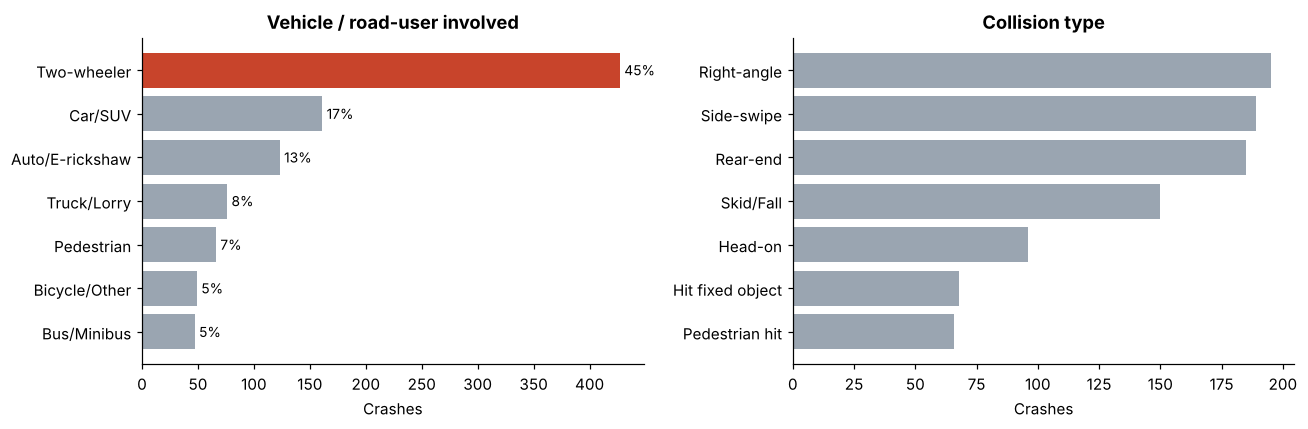

Two-wheelers: 45.0%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
v = crashes.vehicle_type.value_counts()
axes[0].barh(v.index[::-1], v.values[::-1], color=[GREY]*(len(v)-1)+[ACC])
for i, val in enumerate(v.values[::-1]): axes[0].text(val+4, i, f"{val/len(crashes):.0%}", va="center", fontsize=9)
axes[0].set_title("Vehicle / road-user involved"); axes[0].set_xlabel("Crashes")
c = crashes.collision_type.value_counts()
axes[1].barh(c.index[::-1], c.values[::-1], color=GREY)
axes[1].set_title("Collision type"); axes[1].set_xlabel("Crashes")
save("04_vehicle_collision")
print(f"Two-wheelers: {(crashes.vehicle_type=='Two-wheeler').mean():.1%}")

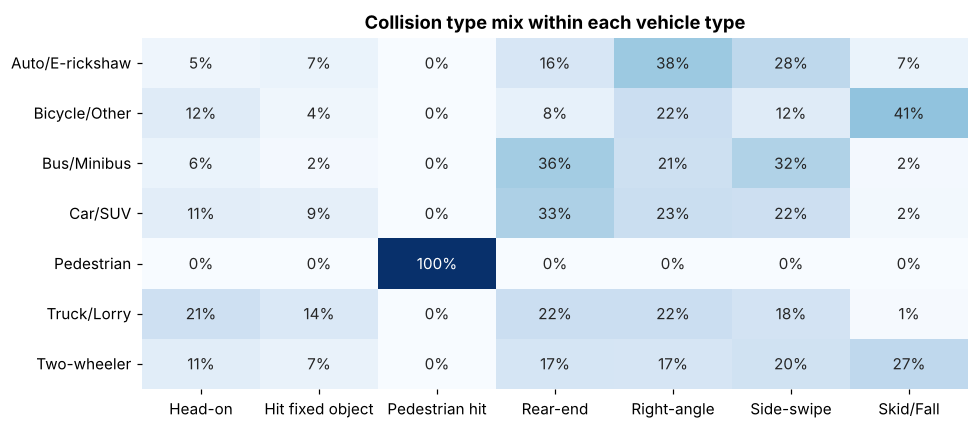

In [8]:
ct = pd.crosstab(crashes.vehicle_type, crashes.collision_type, normalize="index")
fig, ax = plt.subplots(figsize=(9,4))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax)
ax.set(xlabel="", ylabel=""); ax.set_title("Collision type mix within each vehicle type")
save("05_vehicle_by_collision")

## 5 · Severity

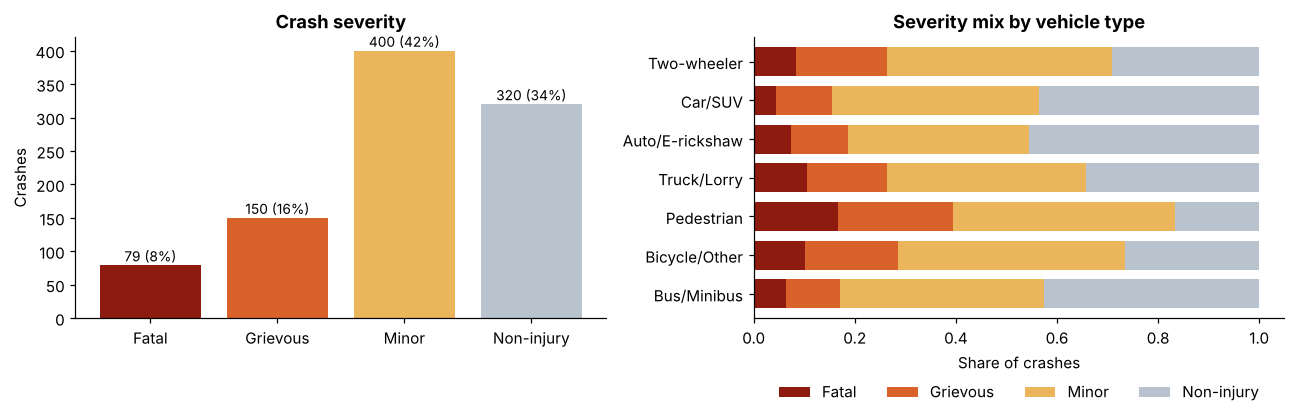

Fatal: 8.3% | Fatal+Grievous: 24.1%


In [9]:
sev = crashes.severity.value_counts().reindex(SEV_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].bar(sev.index, sev.values, color=[SEV_COL[s] for s in sev.index])
for i, val in enumerate(sev.values): axes[0].text(i, val+6, f"{val} ({val/len(crashes):.0%})", ha="center", fontsize=9)
axes[0].set_title("Crash severity"); axes[0].set_ylabel("Crashes")
vs = pd.crosstab(crashes.vehicle_type, crashes.severity, normalize="index")[SEV_ORDER].loc[crashes.vehicle_type.value_counts().index]
vs.plot(kind="barh", stacked=True, ax=axes[1], color=[SEV_COL[s] for s in SEV_ORDER], width=.75)
axes[1].invert_yaxis(); axes[1].set_xlabel("Share of crashes"); axes[1].set_ylabel(""); axes[1].legend(ncol=4, loc="upper center", bbox_to_anchor=(.5,-.18), frameon=False)
axes[1].set_title("Severity mix by vehicle type")
save("06_severity")
print(f"Fatal: {(crashes.severity=='Fatal').mean():.1%} | Fatal+Grievous: {crashes.serious.mean():.1%}")

Serious-crash share — day: 21.9%, night: 32.1%  (χ² p = 0.0033)
Speed-concern score vs crash EPDO (Spearman): ρ=0.17, p=0.0000


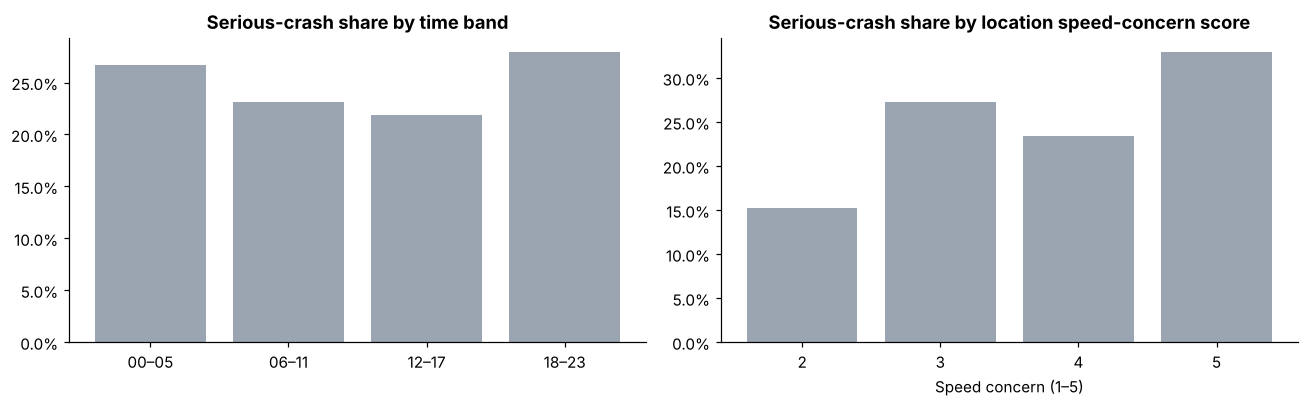

In [10]:
# Is severity different at night? by speed concern?
night_ct = pd.crosstab(crashes.night_flag, crashes.serious)
chi2, p, _, _ = stats.chi2_contingency(night_ct)
print(f"Serious-crash share — day: {crashes[crashes.night_flag==0].serious.mean():.1%}, night: {crashes[crashes.night_flag==1].serious.mean():.1%}  (χ² p = {p:.4f})")
crashes = crashes.merge(locs[["location_id","speed_concern"]], on="location_id", how="left")
rho, pr = stats.spearmanr(crashes.speed_concern, crashes.epdo)
print(f"Speed-concern score vs crash EPDO (Spearman): ρ={rho:.2f}, p={pr:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12,3.8))
hs = crashes.assign(band=pd.cut(crashes.hour, [-1,5,11,17,23], labels=["00–05","06–11","12–17","18–23"])).groupby("band").serious.mean()
axes[0].bar(hs.index.astype(str), hs.values, color=GREY); axes[0].set_title("Serious-crash share by time band"); axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ss = crashes.groupby("speed_concern").serious.mean()
axes[1].bar(ss.index.astype(str), ss.values, color=GREY); axes[1].set_title("Serious-crash share by location speed-concern score"); axes[1].set_xlabel("Speed concern (1–5)"); axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
save("07_severity_drivers")

**Reading:** about one crash in four is fatal or grievous. Two-wheeler riders and pedestrians carry the heaviest severity burden. Night crashes and high-speed locations are more severe, which supports lighting and speed-management interventions.

## 6 · Location profile and EPDO screening

In [11]:
L = (crashes.groupby("location").agg(crashes=("crash_id","size"), epdo=("epdo","sum"), epdo_per_crash=("epdo","mean"),
        fatal=("severity", lambda s:(s=="Fatal").sum()), killed=("persons_killed","sum"))
     .assign(rank_crashes=lambda d: d.crashes.rank(ascending=False, method="min").astype(int),
             rank_epdo=lambda d: d.epdo.rank(ascending=False, method="min").astype(int))
     .sort_values("epdo", ascending=False))
L["rank_shift"] = L.rank_crashes - L.rank_epdo
L.round(2)

,crashes,epdo,epdo_per_crash,fatal,killed,rank_crashes,rank_epdo,rank_shift
location,,,,,,,,
Premtola,140,360,2.57,10,11,1,1,0
Medical College (Ghungoor),103,311,3.02,11,13,2,2,0
Tarapur,95,272,2.86,10,12,4,3,1
NIT Point,99,254,2.57,6,8,3,4,-1
Rangirkhari,82,235,2.87,10,11,5,5,0
Railway Station,75,176,2.35,5,5,7,6,1
Fatak Bazar,76,156,2.05,4,4,6,7,-1
Link Road,48,145,3.02,6,8,9,8,1
Silchar-Kalain Rd (Irongmara),38,138,3.63,5,6,11,9,2


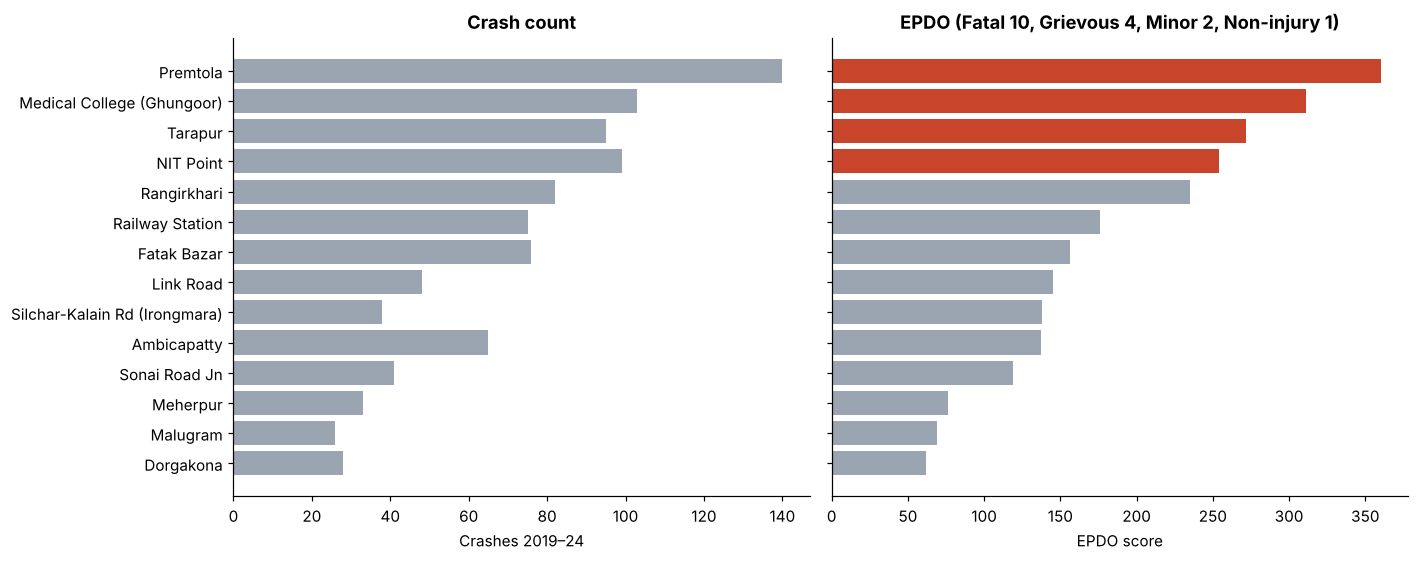

Fatak Bazar: rank by crashes = 6 | by EPDO = 7
Rank agreement crashes vs EPDO: Spearman ρ = 0.96


In [12]:
order = L.index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13,5.2), sharey=True)
axes[0].barh(order, L.loc[order,"crashes"], color=GREY); axes[0].set_title("Crash count"); axes[0].set_xlabel("Crashes 2019–24")
axes[1].barh(order, L.loc[order,"epdo"], color=[ACC if i in L.index[:4] else GREY for i in order]); axes[1].set_title("EPDO (Fatal 10, Grievous 4, Minor 2, Non-injury 1)"); axes[1].set_xlabel("EPDO score")
save("08_location_ranking")
print("Fatak Bazar: rank by crashes =", L.loc['Fatak Bazar','rank_crashes'], "| by EPDO =", L.loc['Fatak Bazar','rank_epdo'])
rho, p = stats.spearmanr(L.rank_crashes, L.rank_epdo); print(f"Rank agreement crashes vs EPDO: Spearman ρ = {rho:.2f}")

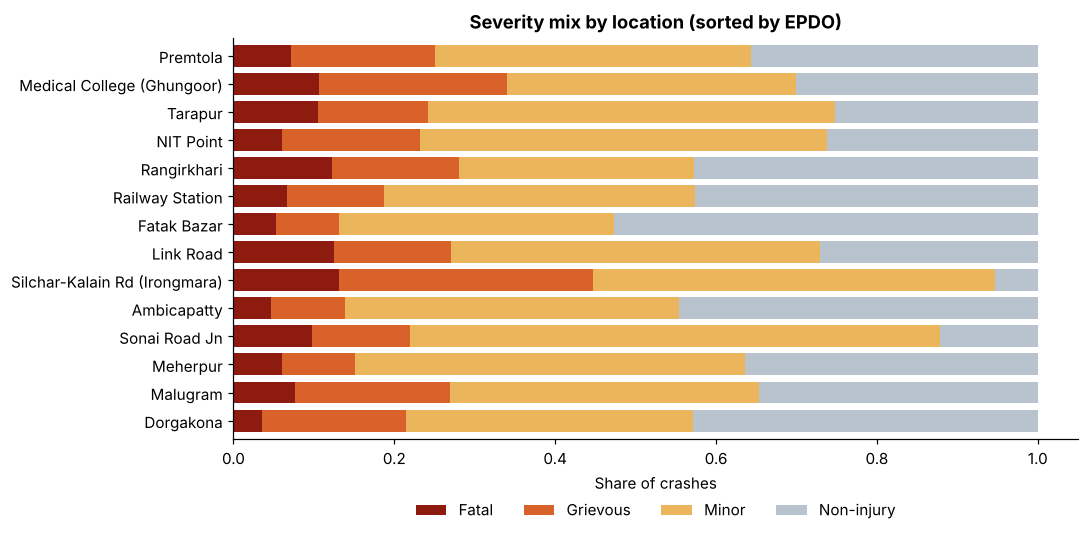

In [13]:
mix = pd.crosstab(crashes.location, crashes.severity, normalize="index")[SEV_ORDER].loc[L.index]
fig, ax = plt.subplots(figsize=(10,5))
mix.iloc[::-1].plot(kind="barh", stacked=True, ax=ax, color=[SEV_COL[s] for s in SEV_ORDER], width=.78)
ax.set_xlabel("Share of crashes"); ax.set_ylabel(""); ax.set_title("Severity mix by location (sorted by EPDO)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(.5,-.12), frameon=False)
save("09_location_severity_mix")

**Reading:** EPDO and raw crash counts largely agree here (ρ ≈ 0.96) — the top five locations are the same under both. The movement is at the margins: Irongmara (Silchar–Kalain Rd) climbs two places because its crashes are the most severe (3.63 EPDO per crash), while Ambicapatty drops two. Fatak Bazar is a busy site with the *lowest* severity per crash (2.05), so its high count overstates its harm. Severity weighting matters most for the mid-table and for low-volume, high-speed peripheral sites; with real data the two rankings would likely diverge more.

## 7 · Exposure attributes vs crashes

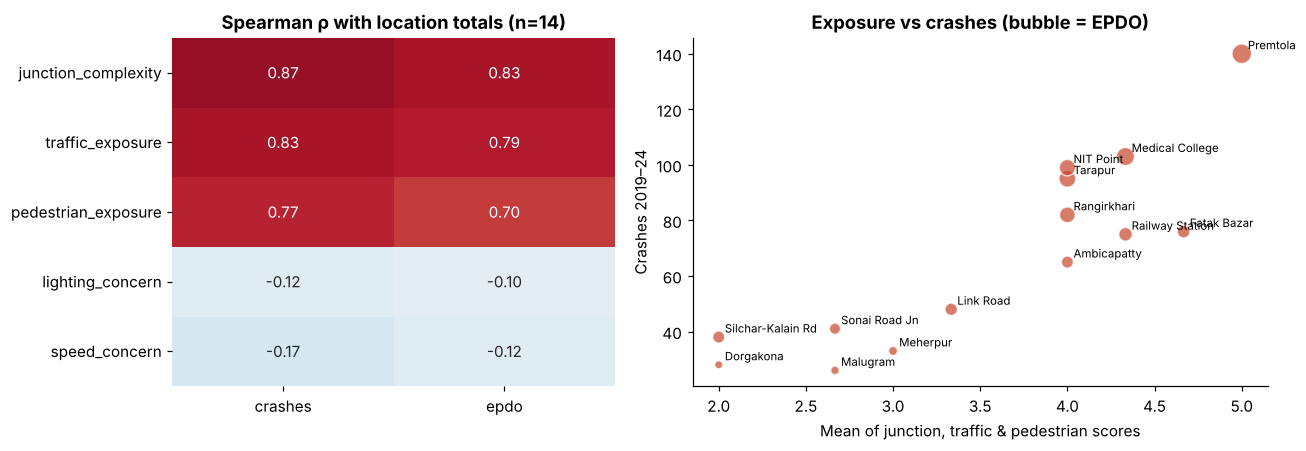

Exposure index vs crash count: ρ=0.84, p=0.0002


In [14]:
lc = locs.merge(L[["crashes","epdo"]], left_on="location", right_index=True)
attrs = ["junction_complexity","traffic_exposure","pedestrian_exposure","lighting_concern","speed_concern"]
corr = lc[attrs+["crashes","epdo"]].corr(method="spearman").loc[attrs, ["crashes","epdo"]]
fig, axes = plt.subplots(1, 2, figsize=(12,4.2), gridspec_kw={"width_ratios":[1,1.3]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Spearman ρ with location totals (n=14)"); axes[0].set_xlabel("")
lc["exposure_idx"] = lc[["junction_complexity","traffic_exposure","pedestrian_exposure"]].mean(axis=1)
axes[1].scatter(lc.exposure_idx, lc.crashes, s=lc.epdo/2.2, color=ACC, alpha=.7, edgecolor="white")
for _, r in lc.iterrows(): axes[1].annotate(r.location.split(" (")[0], (r.exposure_idx, r.crashes), fontsize=7.5, xytext=(4,3), textcoords="offset points")
axes[1].set(xlabel="Mean of junction, traffic & pedestrian scores", ylabel="Crashes 2019–24"); axes[1].set_title("Exposure vs crashes (bubble = EPDO)")
save("10_exposure_vs_crashes")
r, p = stats.spearmanr(lc.exposure_idx, lc.crashes); print(f"Exposure index vs crash count: ρ={r:.2f}, p={p:.4f}")

In [15]:
zone = lc.assign(zone=locs.zone).groupby("zone").agg(locations=("location","count"), crashes=("crashes","sum"), epdo=("epdo","sum"))
zone["crashes_per_location"] = (zone.crashes/zone.locations).round(1); zone.sort_values("epdo", ascending=False)

,locations,crashes,epdo,crashes_per_location
zone,,,,
Arterial junction,5,311,828,62.2
Commercial core,4,329,798,82.2
Institutional,2,202,565,101.0
Peripheral,3,107,319,35.7


**Reading:** crash totals rise with junction complexity, traffic exposure and pedestrian exposure — the very attributes that feed the composite index. (Expected: the data was generated that way, and this check confirms the generator behaves as documented.) Lighting and speed scores show no positive link with crash *counts* (peripheral roads are quieter but faster and darker); they act on *severity* instead (Section 5). With real data, weak correlations here would signal that the scoring needs recalibration.

## 8 · Spatial first look

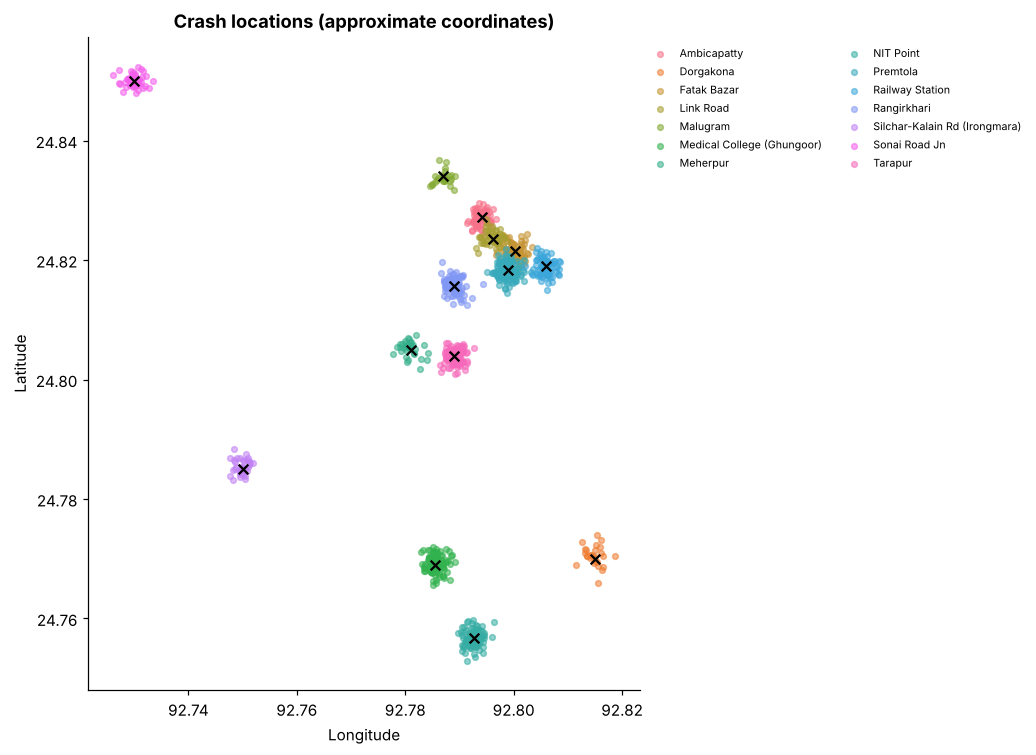

Commercial core (4 locations) holds 35% of crashes within ~2 km — the Premtola–Fatak Bazar zone is the densest area.


In [16]:
fig, ax = plt.subplots(figsize=(8,7))
palette = sns.color_palette("husl", 14)
for (name, g), col in zip(crashes.groupby("location"), palette):
    ax.scatter(g.longitude, g.latitude, s=14, alpha=.55, color=col, label=name)
ax.scatter(locs.longitude, locs.latitude, marker="x", color="black", s=40)
ax.set(xlabel="Longitude", ylabel="Latitude"); ax.set_aspect(1/np.cos(np.radians(24.8)))
ax.set_title("Crash locations (approximate coordinates)"); ax.legend(fontsize=7, ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(1,1))
save("11_spatial_scatter")
core = crashes[crashes.location.isin(["Premtola","Fatak Bazar","Ambicapatty","Link Road"])]
print(f"Commercial core (4 locations) holds {len(core)/len(crashes):.0%} of crashes within ~2 km — the Premtola–Fatak Bazar zone is the densest area.")

*Kernel density estimation and DBSCAN clustering (the next stage) build on this scatter.*

## 9 · Distribution of monthly counts (why month-level prediction is noisy)

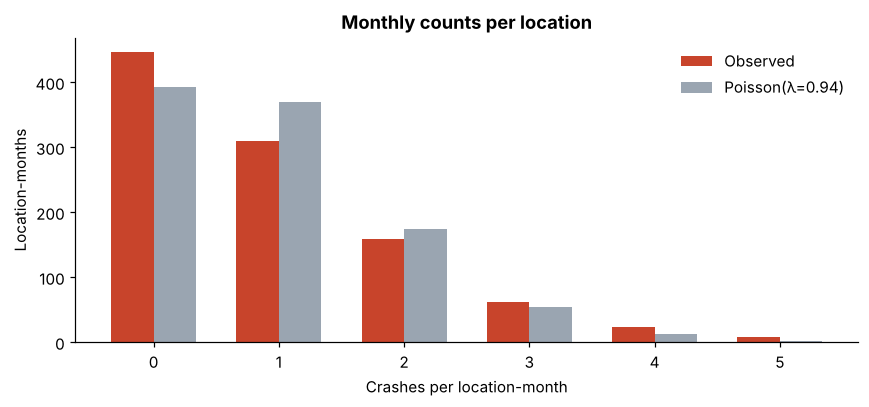

Mean 0.94, variance 1.19 (variance/mean = 1.26; >1 means overdispersion, as location heterogeneity adds variance)
High-risk label (≥2 crashes in a month): 25.1% of location-months
Share of location-months with zero crashes: 44.2%


In [17]:
obs = panel.crash_count.value_counts().sort_index()
lam = panel.crash_count.mean()
exp_pois = pd.Series(stats.poisson.pmf(obs.index, lam)*len(panel), index=obs.index)
fig, ax = plt.subplots(figsize=(8,3.8))
ax.bar(obs.index-.17, obs.values, .34, color=ACC, label="Observed"); ax.bar(obs.index+.17, exp_pois.values, .34, color=GREY, label=f"Poisson(λ={lam:.2f})")
ax.set(xlabel="Crashes per location-month", ylabel="Location-months"); ax.legend(frameon=False); ax.set_title("Monthly counts per location")
save("12_count_distribution")
print(f"Mean {lam:.2f}, variance {panel.crash_count.var():.2f} (variance/mean = {panel.crash_count.var()/lam:.2f}; >1 means overdispersion, as location heterogeneity adds variance)")
print(f"High-risk label (≥2 crashes in a month): {panel.high_risk_month.mean():.1%} of location-months")
print("Share of location-months with zero crashes:", f"{(panel.crash_count==0).mean():.1%}")

**Reading:** most location-months have 0–2 crashes, so monthly counts are small and noisy. The variance exceeds the mean because locations differ in risk. This is the reason the later model ranks locations well but struggles with single months.

## 10 · Key findings

In [18]:
h = crashes.hour.value_counts()
findings = pd.DataFrame([
 ("Records / locations / months", f"{len(crashes)} / {crashes.location.nunique()} / 72"),
 ("Peak hour", f"{h.idxmax()}:00–{h.idxmax()+1}:00 ({h.max()/len(crashes):.0%} of crashes)"),
 ("Night crashes (19:00–05:59)", f"{crashes.night_flag.mean():.0%}"),
 ("Monsoon (May–Sep) share", f"{crashes.monsoon_flag.mean():.0%} vs {5/12:.0%} of calendar"),
 ("Two-wheeler involvement", f"{(crashes.vehicle_type=='Two-wheeler').mean():.0%}"),
 ("Fatal / Fatal+Grievous", f"{(crashes.severity=='Fatal').sum()} ({(crashes.severity=='Fatal').mean():.1%}) / {crashes.serious.mean():.0%}"),
 ("Top 4 locations by EPDO", ", ".join(L.index[:4])),
 ("Highest EPDO per crash", f"{L.epdo_per_crash.idxmax()} ({L.epdo_per_crash.max():.2f})"),
 ("Months with ≥2 crashes", f"{panel.high_risk_month.mean():.0%}"),
], columns=["Metric","Result"]); findings

,Metric,Result
0,Records / locations / months,949 / 14 / 72
1,Peak hour,17:00–18:00 (13% of crashes)
2,Night crashes (19:00–05:59),22%
3,Monsoon (May–Sep) share,45% vs 42% of calendar
4,Two-wheeler involvement,45%
5,Fatal / Fatal+Grievous,79 (8.3%) / 24%
6,Top 4 locations by EPDO,"Premtola, Medical College (Ghungoor), Tarapur,..."
7,Highest EPDO per crash,Silchar-Kalain Rd (Irongmara) (3.63)
8,Months with ≥2 crashes,25%


### Takeaways
1. Crashes concentrate in the **evening peak** and the monsoon, so enforcement and lighting should be timed accordingly.
2. **Two-wheelers and pedestrians** are the key road-user groups; they have the worst severity outcomes.
3. **EPDO barely changes the top of the ranking** but separates high-volume/low-severity sites (Fatak Bazar) from low-volume/high-severity ones (Irongmara).
4. Risk is explained by **junction, traffic and pedestrian exposure**, which supports the composite index design.
5. Monthly counts are **sparse and overdispersed**: rank locations, not single months.

*Next stages (not in this notebook): composite risk index, KDE/DBSCAN hotspot mapping, and ML prediction.*